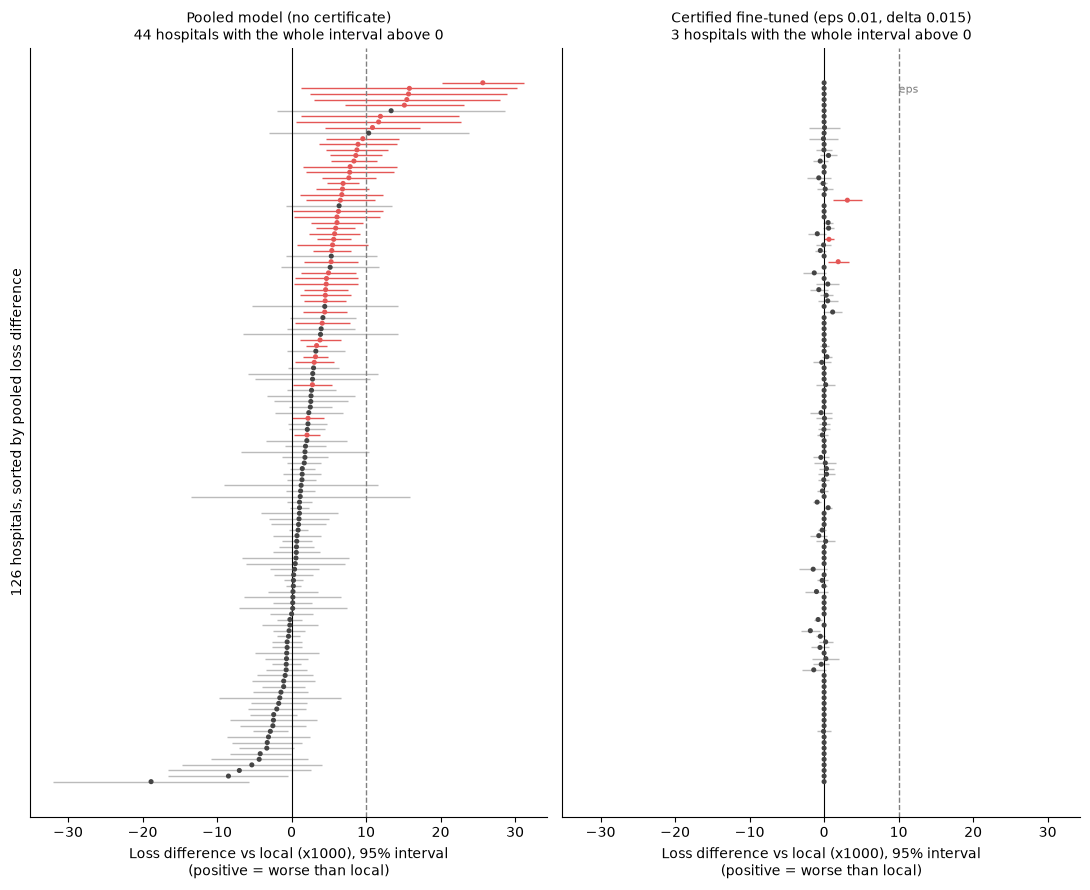

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
R = pd.read_csv("../outputs/tables/cert_full_seed110.csv").copy()
EPS_, DEL_ = 0.01, 0.015
R = R.sort_values("pool_full__diff").reset_index(drop=True)
yy = np.arange(len(R))

fig, ax = plt.subplots(1, 2, figsize=(11, 9), sharey=True)
for a, pre, title in [(ax[0], "pool_full", "Pooled model (no certificate)"),
                      (ax[1], f"cert_ft_e{EPS_}_d{DEL_}", f"Certified fine-tuned (eps {EPS_}, delta {DEL_})")]:
    d, se = 1000 * R[f"{pre}__diff"], 1000 * R[f"{pre}__se"]
    lo, hi = d - 1.96 * se, d + 1.96 * se
    bad = lo > 0
    a.hlines(yy, lo, hi, color=np.where(bad, "#E45756", "#bbbbbb"), lw=1)
    a.scatter(d, yy, s=7, c=np.where(bad, "#E45756", "#444444"), zorder=3)
    a.axvline(0, c="k", lw=0.8); a.axvline(1000 * EPS_, c="grey", ls="--", lw=1)
    a.set_title(f"{title}\n{int(bad.sum())} hospitals with the whole interval above 0", fontsize=10)
    a.set_xlabel("Loss difference vs local (x1000), 95% interval\n(positive = worse than local)")
ax[0].set_ylabel("126 hospitals, sorted by pooled loss difference"); ax[0].set_yticks([])
ax[1].text(1000 * EPS_, len(R) * 0.99, "eps", fontsize=8, ha="left", va="top", color="grey")
ax[1].set_xlim(ax[0].get_xlim())
plt.tight_layout(); plt.savefig("../outputs/figures/fig6_forest.png", dpi=300); plt.savefig("../outputs/figures/fig6_forest.pdf"); plt.show()

      eps  delta                            method  loss_harm  cal_harm  either  point_above  nonlocal_  mean_loss_diff  auroc_gain  max_either_over_seeds  max_point_above
0   0.005  0.010         Pooled, hospital included        0.6       4.8     5.2         68.8        NaN          0.0029      0.0005                      7               70
1   0.005  0.010         Pooled, hospital left out        0.8       5.0     5.6         69.2        NaN          0.0031      0.0002                      7               70
2   0.005  0.010      Certified, hospital included        0.0       0.0     0.0          0.0       17.0          0.0000      0.0002                      0                0
3   0.005  0.010  Certified, new-hospital protocol        0.0       0.0     0.0          0.0       16.8          0.0000      0.0002                      0                0
4   0.010  0.015         Pooled, hospital included        0.4       2.0     2.4         48.8        NaN          0.0029      0.0005         

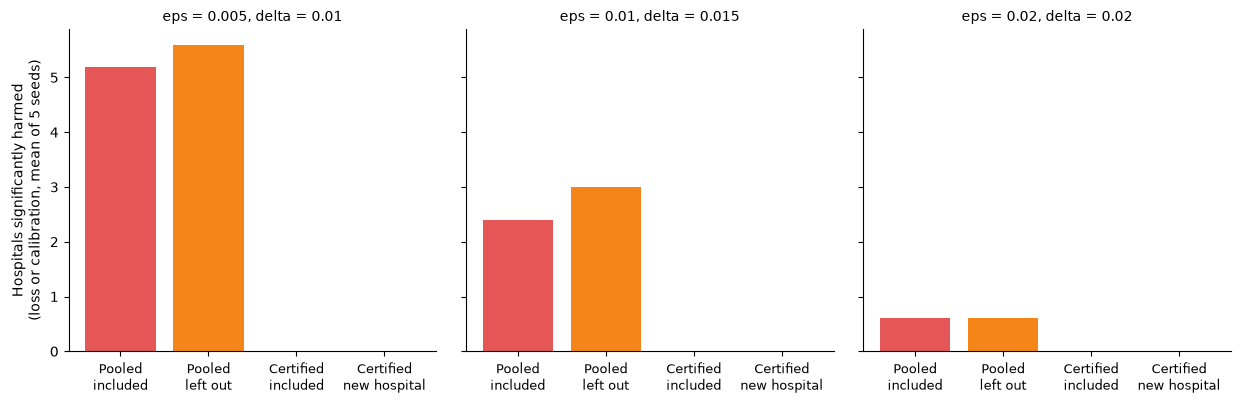

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
seeds = [110, 111, 112, 113, 114]; HEAD = [(0.005, 0.01), (0.01, 0.015), (0.02, 0.02)]
L = {s: pd.read_csv(f"../outputs/tables/loho_seed{s}.csv").copy() for s in seeds}
A = {s: pd.read_csv(f"../outputs/tables/cert_full_seed{s}.csv").copy() for s in seeds}

def lm(r, pre, eps):
    d, se = r[f"{pre}__diff"].values, r[f"{pre}__se"].values
    z = np.where(se > 0, (d - eps) / np.where(se > 0, se, 1), -np.inf)
    return multipletests(1 - stats.norm.cdf(z), alpha=0.05, method="holm")[0]

rows = []
for eps, delta in HEAD:
    specs = [("Pooled, hospital included", A, "pool_full"), ("Pooled, hospital left out", L, "pool_full"),
             ("Certified, hospital included", A, f"cert_pool_e{eps}_d{delta}"), ("Certified, new-hospital protocol", L, f"cert_e{eps}_d{delta}")]
    for label, D, pre in specs:
        out = []
        for s in seeds:
            r = D[s]; l = lm(r, pre, eps); c = r[f"{pre}__gaplb"].values > delta
            out.append(dict(loss_harm=l.sum(), cal_harm=c.sum(), either=(l | c).sum(), point_above=(r[f"{pre}__gapmax"] > delta).sum(),
                            nonlocal_=(r[f"{pre}__blend"] > 0).sum() if "cert" in pre else np.nan,
                            mean_loss_diff=r[f"{pre}__diff"].mean(), auroc_gain=(r[f"{pre}__auroc"] - r["local__auroc"]).mean()))
        o = pd.DataFrame(out)
        rows.append({"eps": eps, "delta": delta, "method": label, **o.mean().to_dict(), "max_either_over_seeds": o["either"].max(), "max_point_above": o["point_above"].max()})
T = pd.DataFrame(rows); T.to_csv("../outputs/tables/T_loho.csv", index=False); print(T.round(4).to_string())
c = T[T.method == "Certified, new-hospital protocol"]
print("\ncriterion (new-hospital protocol): max hospitals significantly harmed over seeds =", int(c.max_either_over_seeds.max()),
      "| max above tolerance by point estimate =", int(c.max_point_above.max()))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
labs = ["Pooled\nincluded", "Pooled\nleft out", "Certified\nincluded", "Certified\nnew hospital"]
cols = ["#E45756", "#F58518", "#9ecae1", "#54A24B"]
for a, (eps, delta) in zip(ax, HEAD):
    t = T[(T.eps == eps) & (T.delta == delta)]
    a.bar(range(4), t.either.values, color=cols)
    a.set_xticks(range(4)); a.set_xticklabels(labs, fontsize=9); a.set_title(f"eps = {eps}, delta = {delta}", fontsize=10)
ax[0].set_ylabel("Hospitals significantly harmed\n(loss or calibration, mean of 5 seeds)")
plt.subplots_adjust(wspace=0.08, bottom=0.18)
plt.savefig("../outputs/figures/fig21_loho.png", dpi=300); plt.savefig("../outputs/figures/fig21_loho.pdf"); plt.show()